In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob

data-5pri-001.csv


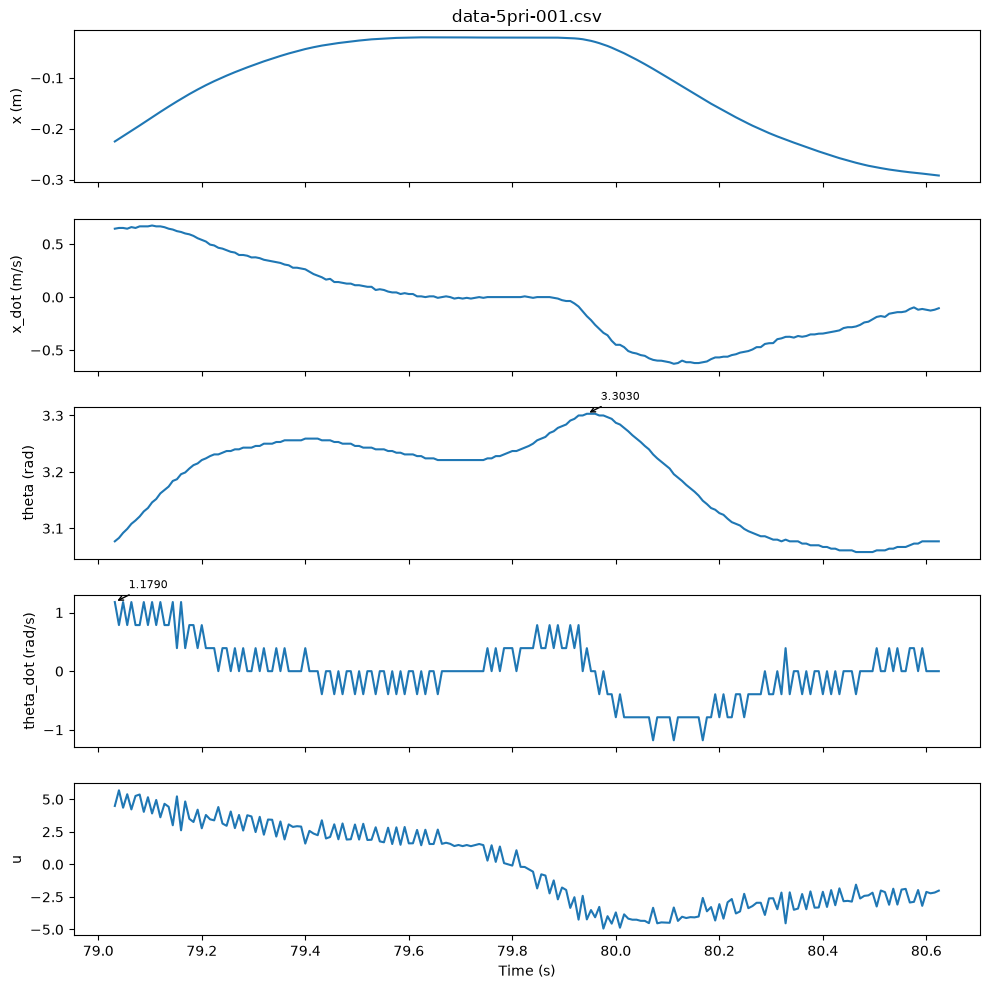

data-7pri-001.csv


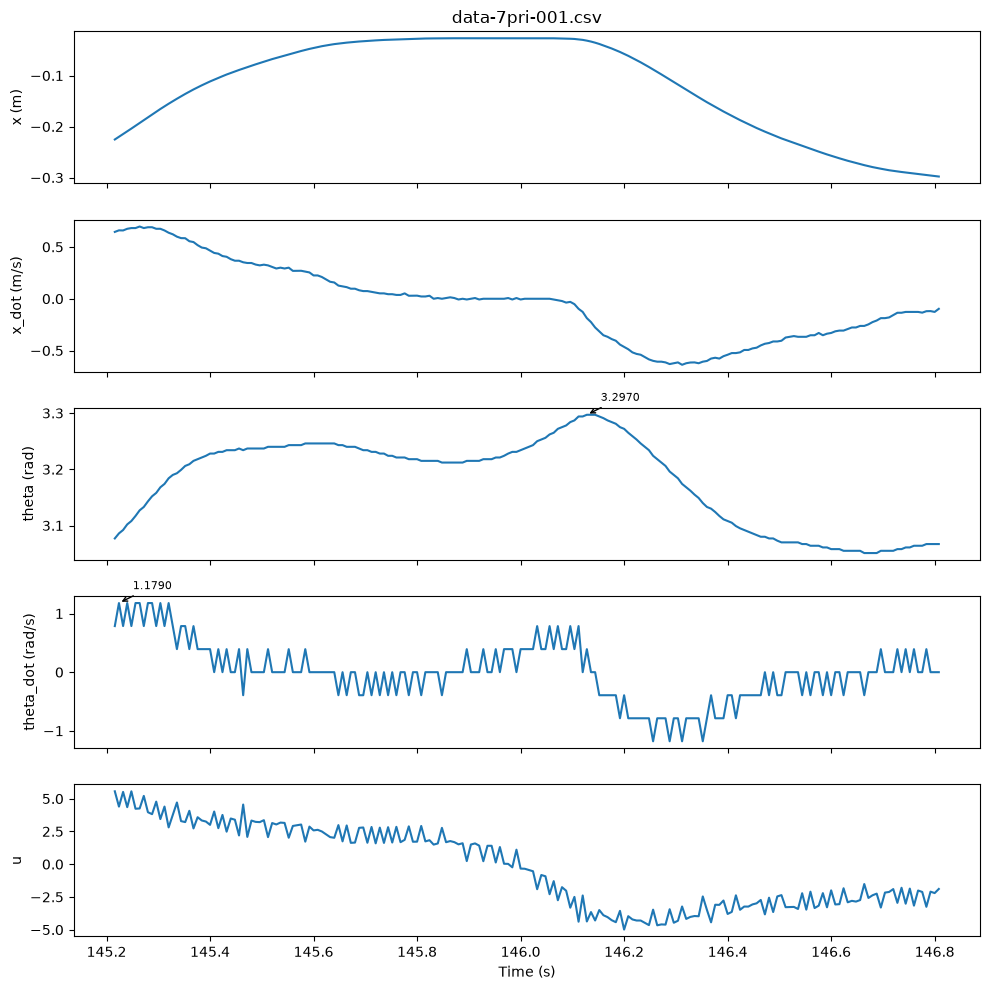

In [3]:
folder_name = "fixed"  # choose from: baseline_unstable, every5, lpf, lpf03, normal_operation

folder_path = os.path.join(os.getcwd(), folder_name)
csv_files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))

for csv_file in csv_files:
    print(os.path.basename(csv_file))
    df = pd.read_csv(csv_file)
    df = df.sort_values("timestamp_ms").reset_index(drop=True)

    time_s = df["timestamp_ms"] / 1000.0
    x = df["x_e4"] / 10000.0
    xdot = df["xdot_e3"] / 1000.0
    theta = df["theta_e3"] / 1000.0
    thetadot = df["thetadot_e3"] / 1000.0
    u = df["u_e3"] / 1000.0

    fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)

    axes[0].plot(time_s, x)
    axes[0].set_ylabel("x (m)")
    axes[0].set_title(os.path.basename(csv_file))

    axes[1].plot(time_s, xdot)
    axes[1].set_ylabel("x_dot (m/s)")

    axes[2].plot(time_s, theta)
    axes[2].set_ylabel("theta (rad)")

    theta_abs_max_idx = theta.abs().idxmax()
    axes[2].annotate(f"{theta.iloc[theta_abs_max_idx]:.4f}",
                     xy=(time_s.iloc[theta_abs_max_idx], theta.iloc[theta_abs_max_idx]),
                     xytext=(10, 10), textcoords="offset points",
                     arrowprops=dict(arrowstyle="->"), fontsize=8)

    axes[3].plot(time_s, thetadot)
    axes[3].set_ylabel("theta_dot (rad/s)")

    thetadot_abs_max_idx = thetadot.abs().idxmax()
    axes[3].annotate(f"{thetadot.iloc[thetadot_abs_max_idx]:.4f}",
                     xy=(time_s.iloc[thetadot_abs_max_idx], thetadot.iloc[thetadot_abs_max_idx]),
                     xytext=(10, 10), textcoords="offset points",
                     arrowprops=dict(arrowstyle="->"), fontsize=8)

    axes[4].plot(time_s, u)
    axes[4].set_ylabel("u")
    axes[4].set_xlabel("Time (s)")

    plt.tight_layout()
    tif_path = os.path.join(folder_path, os.path.basename(csv_file).replace(".csv", ".tif"))
    fig.savefig(tif_path, dpi=150)
    plt.show()